# CS156 Pipeline 1: HC/LO tag classification from Minerva assignment footnotes

Data: `data/processed/sections.csv` (built by `src/extract_sections.py` from the submission PDFs listed in `data/inventory.tsv`). Code in `src/`. Run top to bottom.

## 1. Load data

In [1]:
import sys, warnings, itertools, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
from dataset import build_table, tag_summary
from tags import FAMILY_NAMES
from evaluate import make_models, cross_validate, learning_curve, top_words_nb
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

apps, mentions = build_table("../data/processed/sections.csv")
inv = pd.read_csv("../data/inventory.tsv", sep="\t")
print(f"inventory: {len(inv)} assignments, {inv.course.nunique()} courses, {inv.due.min()} to {inv.due.max()}")
print(f"tag applications (footnote + body justification): {len(apps)} from {apps.assignment_id.nunique()} assignments; mentions: {len(mentions)}")
print("\nby source:"); print(apps.source.value_counts().to_string())
print("\nby family:"); print(apps.family.map(FAMILY_NAMES).value_counts().to_string())
print("\nfamily assigned by rule:"); print(apps.family_rule.value_counts().to_string())

inventory: 152 assignments, 36 courses, 2023-09-20 to 2026-09-26
tag applications (footnote + body justification): 336 from 70 assignments; mentions: 312

by source:
source
footnote              196
body_justification    140

by family:
family
Course learning outcome      100
Complex Systems               72
Empirical Analyses            66
Multimodal Communications     62
Formal Analyses               36

family assigned by rule:
family_rule
usage       192
LO          100
handbook     44


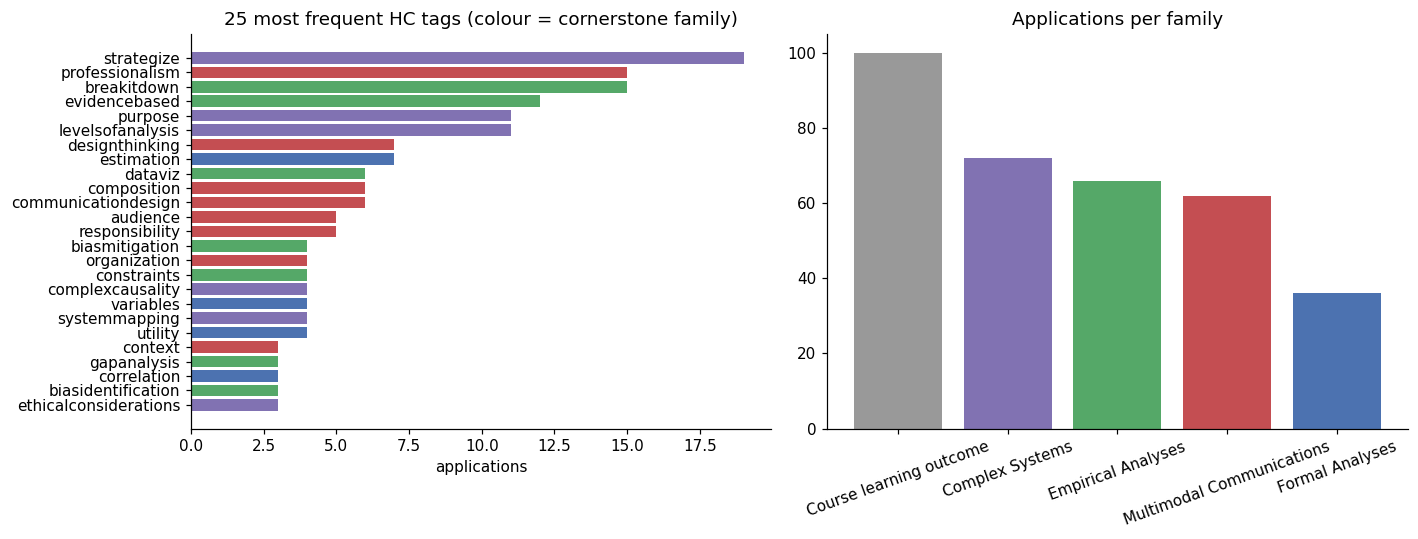

69 distinct HC tags; 13 of them have >=5 applications


In [2]:
summ = tag_summary(apps)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
top = summ[summ.family != "LO"].head(25)
colors = {"FA": "#4c72b0", "EA": "#55a868", "MC": "#c44e52", "CX": "#8172b2", "LO": "#999999"}
ax[0].barh(top.tag[::-1], top.n[::-1], color=[colors[f] for f in top.family[::-1]])
ax[0].set_title("25 most frequent HC tags (colour = cornerstone family)"); ax[0].set_xlabel("applications")
fam = apps.family.value_counts()
ax[1].bar([FAMILY_NAMES[f] for f in fam.index], fam.values, color=[colors[f] for f in fam.index])
ax[1].set_title("Applications per family"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("../figures/tag_distribution.png", bbox_inches="tight"); plt.show()
print(f"{summ[summ.family!='LO'].shape[0]} distinct HC tags; {(summ[summ.family!='LO'].n>=5).sum()} of them have >=5 applications")

## 2. Example row (context vs justification, masked vs unmasked)

In [3]:
ex = apps[(apps.tag == "breakitdown") & (apps.context.str.len() > 200)].iloc[0]
print(f"{ex.course} | {ex.title} | page {ex.page} | footnote {int(ex.marker)} | tag #{ex.tag} | family {ex.family}\n")
print("CONTEXT (body text before the marker):\n ", ex.text_context[:500], "\n")
print("JUSTIFICATION (footnote):\n ", ex.text_justification[:500], "\n")
print("JUSTIFICATION, masked:\n ", ex.text_justification_masked[:500])

B110 | Experimental Design Paper | page 3 | footnote 1 | tag #breakitdown | family EA

CONTEXT (body text before the marker):
  Also, cultural differences influence the extent to which individuals experience the endowment effect. Experiment Proposal To test this hypothesis, I propose an experiment that will explore the endowment effect in two different product categories - high-stakes items (such as cars or real estate) and low-stakes items (such as mugs or chocolates) - across different cultural contexts. This will allow me to see whether the endowment effect operates differently based on the product's perceived value o 

JUSTIFICATION (footnote):
  In designing the experiment, I broke down the larger problem of understanding the endowment effect into smaller components: like for example focusing on the product type (high-stakes vs. low-stakes) and the cultural context (Western vs. Eastern). This allows for a more focused approach to analyzing the effect in each category, making the p

## 3. Family task: model x text view x masking (5-fold StratifiedGroupKFold by assignment)

Text views: `justification` (footnote text), `context` (last three sentences before the marker), `both`. Masked = tag name and its paraphrases removed. Metrics: accuracy, macro-F1, hit@3.

In [4]:
VIEWS = ["justification", "context", "both"]
MODELS = list(make_models().keys())

def run_grid(df, label_col, tag2family=None, views=VIEWS, masks=(False, True), models=MODELS, seed=0):
    rows = []
    for view, masked, name in itertools.product(views, masks, models):
        col = f"text_{view}" + ("_masked" if masked else "")
        d = df[df[col].str.split().str.len() >= 3]
        model = make_models(seed)[name]
        summ, folds, yt, yp = cross_validate(d[col], d[label_col], d.assignment_id, model, tag2family=tag2family)
        r = dict(text_view=view, masked=masked, model=name, n=len(d))
        for m in summ.columns:
            r[m] = summ.loc["mean", m]; r[m + "_sd"] = summ.loc["std", m]
        r["_pred"] = (yt, yp)
        rows.append(r)
    return pd.DataFrame(rows)

resA = run_grid(apps, "family")
tabA = resA.pivot_table(index=["text_view", "masked"], columns="model", values="macro_f1").round(3)[MODELS]
print("Experiment A, family (5 classes): macro-F1, mean over 5 grouped folds")
display(tabA)
print("\naccuracy:"); display(resA.pivot_table(index=["text_view", "masked"], columns="model", values="accuracy").round(3)[MODELS])

Experiment A, family (5 classes): macro-F1, mean over 5 grouped folds


model                 majority  nb_counts  logreg_tfidf  tree_tfidf  svm_tfidf
text_view     masked                                                          
both          False      0.092      0.559         0.566       0.267      0.597
              True       0.092      0.517         0.518       0.269      0.540
context       False      0.061      0.451         0.397       0.159      0.404
              True       0.061      0.437         0.379       0.165      0.403
justification False      0.092      0.569         0.597       0.248      0.614
              True       0.092      0.523         0.522       0.242      0.552


accuracy:


model                 majority  nb_counts  logreg_tfidf  tree_tfidf  svm_tfidf
text_view     masked                                                          
both          False      0.298      0.631         0.629       0.362      0.648
              True       0.298      0.594         0.606       0.355      0.616
context       False      0.192      0.502         0.459       0.208      0.466
              True       0.192      0.495         0.443       0.241      0.461
justification False      0.298      0.660         0.664       0.346      0.679
              True       0.298      0.628         0.618       0.340      0.640

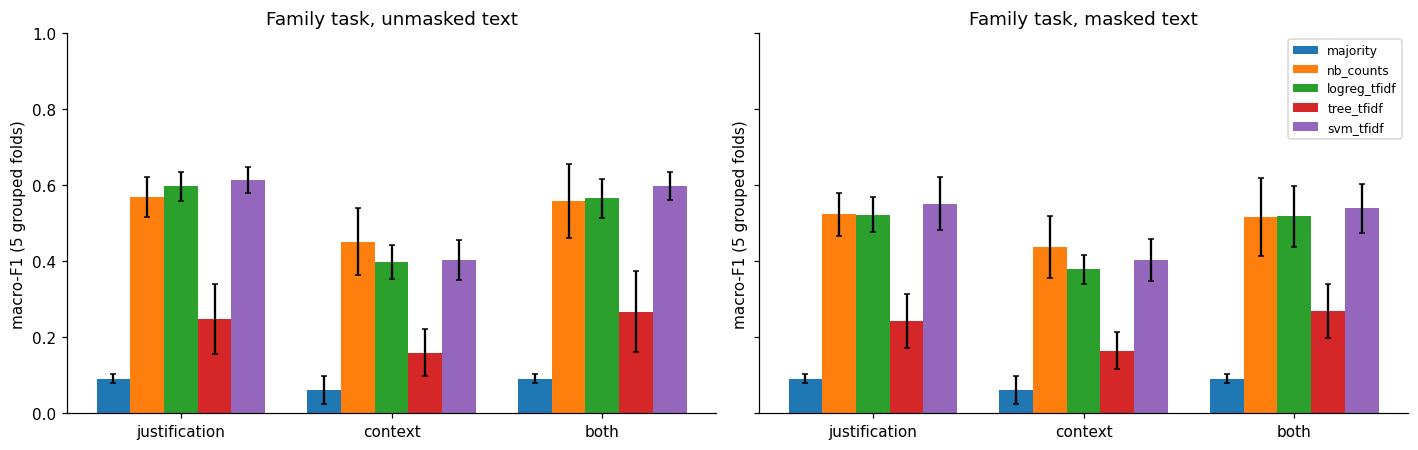

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, masked in zip(axes, [False, True]):
    sub = resA[resA.masked == masked]
    x = np.arange(len(VIEWS)); wdt = 0.16
    for i, m in enumerate(MODELS):
        s = sub[sub.model == m].set_index("text_view").loc[VIEWS]
        ax.bar(x + (i - 2) * wdt, s.macro_f1, wdt, yerr=s.macro_f1_sd, capsize=2, label=m)
    ax.set_xticks(x); ax.set_xticklabels(VIEWS); ax.set_ylim(0, 1)
    ax.set_title(f"Family task, {'masked' if masked else 'unmasked'} text"); ax.set_ylabel("macro-F1 (5 grouped folds)")
axes[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig("../figures/condition_grid_family.png", bbox_inches="tight"); plt.show()

best masked family model: svm_tfidf on 'justification', macro-F1 0.552 +/- 0.070, accuracy 0.640


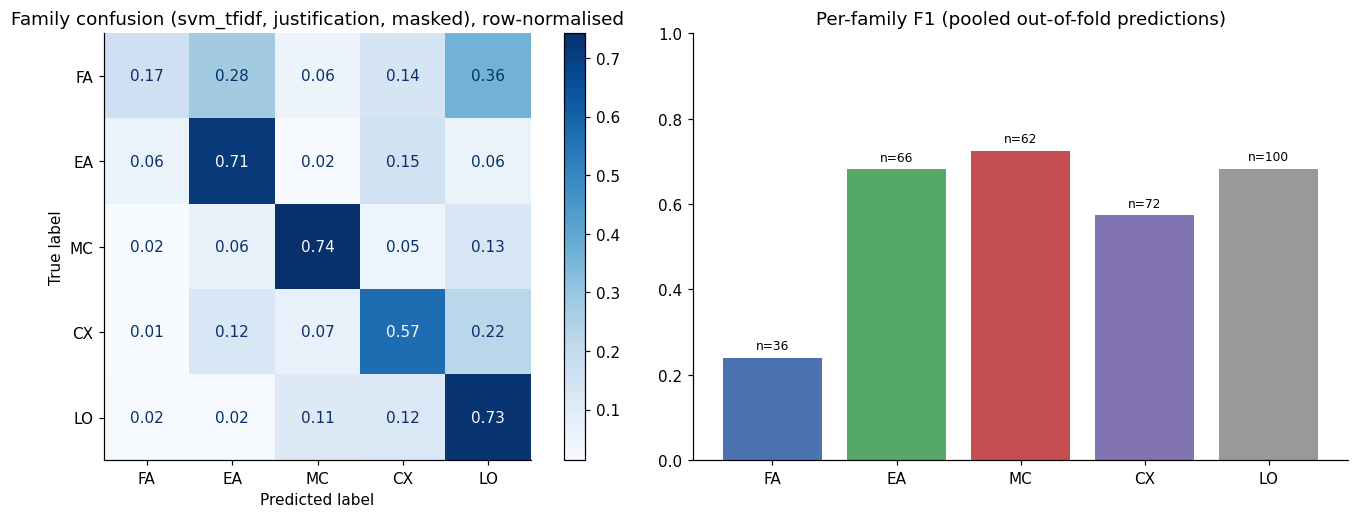

,precision,recall,f1-score,support
FA,0.429,0.167,0.240,36.0
EA,0.653,0.712,0.681,66.0
MC,0.708,0.742,0.724,62.0
CX,0.577,0.569,0.573,72.0
LO,0.640,0.730,0.682,100.0


In [6]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
best = resA[(resA.masked == True) & (resA.model != "majority")].sort_values("macro_f1", ascending=False).iloc[0]
print(f"best masked family model: {best.model} on '{best.text_view}', macro-F1 {best.macro_f1:.3f} +/- {best.macro_f1_sd:.3f}, accuracy {best.accuracy:.3f}")
yt, yp = best._pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay.from_predictions(yt, yp, labels=["FA", "EA", "MC", "CX", "LO"], normalize="true", ax=axes[0], cmap="Blues", values_format=".2f")
axes[0].set_title(f"Family confusion ({best.model}, {best.text_view}, masked), row-normalised")
rep = pd.DataFrame(classification_report(yt, yp, output_dict=True, zero_division=0)).T.loc[["FA", "EA", "MC", "CX", "LO"]]
axes[1].bar(rep.index, rep["f1-score"], color=[colors[f] for f in rep.index]); axes[1].set_ylim(0, 1)
axes[1].set_title("Per-family F1 (pooled out-of-fold predictions)")
for i, (f, n) in enumerate(zip(rep.index, rep.support)): axes[1].text(i, rep["f1-score"].iloc[i] + 0.02, f"n={int(n)}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig("../figures/family_confusion.png", bbox_inches="tight"); plt.show()
display(rep.round(3))

In [7]:
# Naive Bayes: most indicative words per family (masked justifications, fitted on all rows)
nb = make_models()["nb_counts"].fit(apps.text_justification_masked, apps.family)
tw = top_words_nb(nb, n=14)
display(pd.DataFrame({FAMILY_NAMES[k]: v for k, v in tw.items()}))

,Complex Systems,Empirical Analyses,Formal Analyses,Course learning outcome,Multimodal Communications
0,tesla,tractable,glucose,levi,video
1,diagnosis,biases,glucose levels,sales,style
2,mission,polluted,intervals,global,writing
3,societal,hypothesis,interpreted,3b,professional
4,abortion,treatment,estimate,unit,narrative
5,leverage points,migration,statistical,cash flows,word
6,actions,temperature,pregnancies,customer,word count
7,astrological,genetic,sample,consumer,viewers
8,guiding policy,killifish,inductive,flows,mary
9,values,problem,approximated,operational,guidelines


## 4. Fine-grained tag task (tags with >=5 applications): macro-F1, hit@3, family consistency

In [8]:
vc = apps[apps.family != "LO"].tag.value_counts()
fine = apps[apps.tag.isin(vc[vc >= 5].index)].copy()
tag2family = dict(zip(fine.tag, fine.family))
print(f"fine task: {len(fine)} applications, {fine.tag.nunique()} tags, {fine.assignment_id.nunique()} assignments")
resB = run_grid(fine, "tag", tag2family=tag2family, views=["justification", "both"], models=[m for m in MODELS if m != "tree_tfidf"])
tabB = resB.pivot_table(index=["text_view", "masked"], columns="model", values=["macro_f1", "hit_at_k", "family_consistency"]).round(3)
display(tabB)

fine task: 125 applications, 13 tags, 58 assignments


family_consistency                               \
model                      logreg_tfidf majority nb_counts svm_tfidf   
text_view     masked                                                   
both          False               0.898    0.272     0.895     0.921   
              True                0.847    0.272     0.833     0.873   
justification False               0.927    0.272     0.902     0.937   
              True                0.883    0.272     0.826     0.904   

                         hit_at_k                                  macro_f1  \
model                logreg_tfidf majority nb_counts svm_tfidf logreg_tfidf   
text_view     masked                                                          
both          False         0.898    0.258     0.893     0.929        0.707   
              True          0.810    0.258     0.806     0.851        0.573   
justification False         0.910    0.258     0.915     0.953        0.792   
              True          0.832    0.258     0.851     0.873        0.637   

                                                   
model                majority nb_counts svm_tfidf  
text_view     masked                               
both          False     0.018     0.730     0.802  
              True      0.018     0.613     0.654  
justification False     0.018     0.746     0.817  
              True      0.018     0.606     0.683

best masked fine model: svm_tfidf on 'justification', hit@3 0.873, macro-F1 0.683, family consistency 0.904


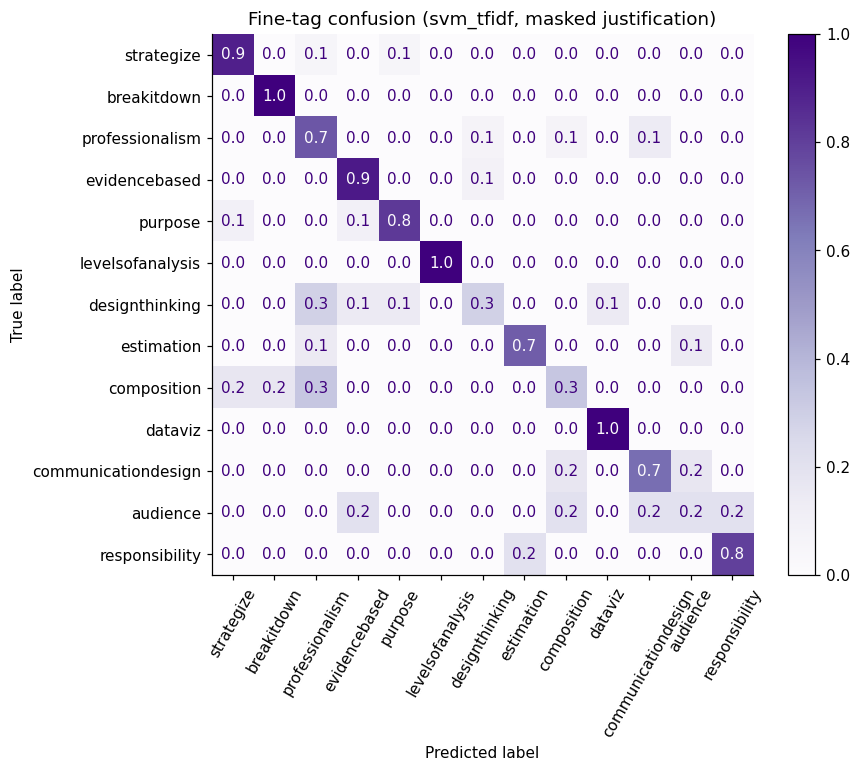

In [9]:
bestB = resB[(resB.masked == True) & (resB.model != "majority")].sort_values("hit_at_k", ascending=False).iloc[0]
print(f"best masked fine model: {bestB.model} on '{bestB.text_view}', hit@3 {bestB.hit_at_k:.3f}, macro-F1 {bestB.macro_f1:.3f}, family consistency {bestB.family_consistency:.3f}")
yt, yp = bestB._pred
order = list(vc[vc >= 5].index)
fig, ax = plt.subplots(figsize=(8.5, 7))
ConfusionMatrixDisplay.from_predictions(yt, yp, labels=order, normalize="true", ax=ax, cmap="Purples", values_format=".1f", xticks_rotation=60)
ax.set_title(f"Fine-tag confusion ({bestB.model}, masked {bestB.text_view})")
plt.tight_layout(); plt.savefig("../figures/fine_confusion.png", bbox_inches="tight"); plt.show()

## 5. Training-data condition: context view with and without plain mentions

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score
def augmented_cv(model_name, masked, seed=0):
    col = "text_context" + ("_masked" if masked else "")
    d = apps[apps[col].str.split().str.len() >= 3].reset_index(drop=True)
    m_ = mentions[mentions[col].str.split().str.len() >= 3]
    skf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    out = []
    for tr, te in skf.split(d[col], d.family, d.assignment_id):
        test_assign = set(d.assignment_id.iloc[te])
        extra = m_[~m_.assignment_id.isin(test_assign)]
        for aug in (False, True):
            X = pd.concat([d[col].iloc[tr], extra[col]]) if aug else d[col].iloc[tr]
            y = pd.concat([d.family.iloc[tr], extra.family]) if aug else d.family.iloc[tr]
            mod = make_models(seed)[model_name].fit(X, y)
            out.append(dict(aug=aug, f1=f1_score(d.family.iloc[te], mod.predict(d[col].iloc[te]), average="macro", zero_division=0)))
    return pd.DataFrame(out).groupby("aug").f1.agg(["mean", "std"]).round(3)
rows = []
for mn in ["nb_counts", "logreg_tfidf", "svm_tfidf"]:
    for masked in (False, True):
        r = augmented_cv(mn, masked)
        rows.append(dict(model=mn, masked=masked, context_only=r.loc[False, "mean"], context_plus_mentions=r.loc[True, "mean"], sd_plus=r.loc[True, "std"]))
resC = pd.DataFrame(rows); display(resC)

,model,masked,context_only,context_plus_mentions,sd_plus
0,nb_counts,False,0.451,0.445,0.095
1,nb_counts,True,0.437,0.440,0.108
2,logreg_tfidf,False,0.397,0.395,0.043
3,logreg_tfidf,True,0.379,0.395,0.029
4,svm_tfidf,False,0.404,0.393,0.050
5,svm_tfidf,True,0.403,0.375,0.034


## 6. Learning curves

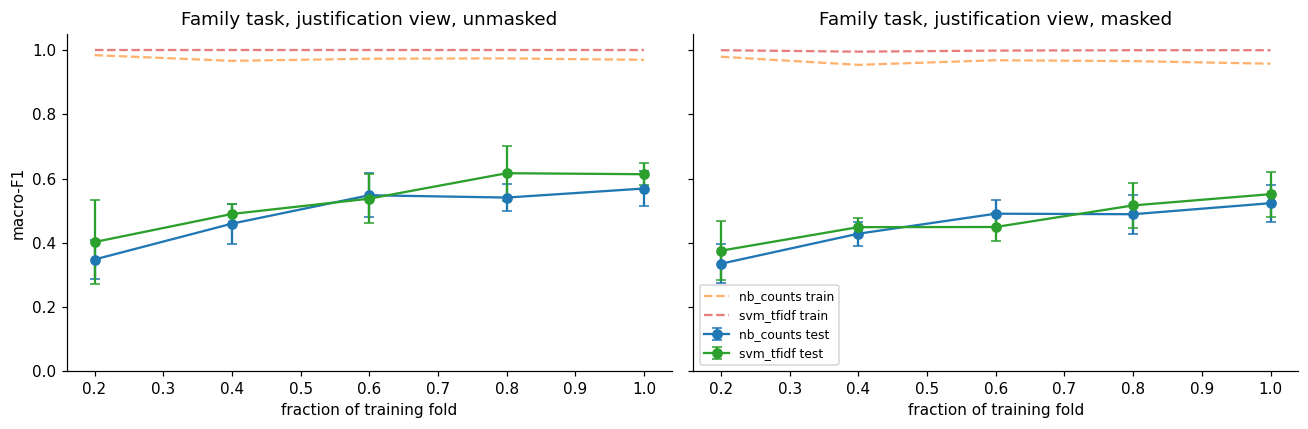

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, masked in zip(axes, [False, True]):
    col = "text_justification" + ("_masked" if masked else "")
    d = apps[apps[col].str.split().str.len() >= 3]
    for mn in ["nb_counts", best.model] if best.model != "nb_counts" else ["nb_counts", "logreg_tfidf"]:
        lc = learning_curve(d[col], d.family, d.assignment_id, lambda: make_models()[mn])
        g = lc.groupby("fraction")[["train_f1", "test_f1"]].agg(["mean", "std"])
        ax.errorbar(g.index, g["test_f1"]["mean"], yerr=g["test_f1"]["std"], marker="o", capsize=3, label=f"{mn} test")
        ax.plot(g.index, g["train_f1"]["mean"], ls="--", alpha=0.6, label=f"{mn} train")
    ax.set_title(f"Family task, justification view, {'masked' if masked else 'unmasked'}"); ax.set_xlabel("fraction of training fold"); ax.set_ylim(0, 1.05)
axes[0].set_ylabel("macro-F1"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("../figures/learning_curves.png", bbox_inches="tight"); plt.show()

All figures are written to `figures/`.